# Module 2: LSTM-Based Multiclass IoT Attack Classification with INT8 Quantization
## Research & Engineering Walkthrough

**Capstone Extension:** IoT Intrusion Detection System (CICIoT2023)  
**Author / Engineering Role:** Senior ML Engineer & IoT Cybersecurity Researcher  
**Core Framework:** TensorFlow / Keras, TensorFlow Lite / LiteRT, NumPy, Scikit-Learn  

---

### Pipeline Overview & Relationship to Module 1
* **Module 1 (First-Line Sentinel):** Inter-Arrival Time (IAT) statistical dispersion ($CV = \sigma/\mu$) and Mamdani Fuzzy Inference System for rapid, unsupervised anomaly filtering.
* **Module 2 (Second-Line Attribution):** A Long Short-Term Memory (LSTM) recurrent neural network that receives anomalous observation sequences ($L=50$) and classifies the specific threat into one of 34 IoT attack categories.
* **Edge Deployment:** Full-integer INT8 post-training quantization reducing inference latency to **< 0.1 ms** for deployment on resource-constrained IoT gateways and Raspberry Pi devices.



## 1. Environment Setup & Library Imports
We initialize the environment and load our modular architecture components.


In [1]:
import os
import sys
from pathlib import Path

# Ensure project root is in python path
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Verify TensorFlow availability
import tensorflow as tf
print(f"TensorFlow Version: {tf.__version__}")
print(f"NumPy Version:      {np.__version__}")



TensorFlow Version: 2.21.0
NumPy Version:      1.26.4


## 2. Dataset Inspection & Label Taxonomy (CICIoT2023)
We examine the Kaggle release `himadri07/ciciot2023`, its column headers, and verify that all 34 classes are accounted for.


In [2]:
from src.module2.config import module2_config

train_path = module2_config.DATASET_DIR / module2_config.TRAIN_FILENAME
test_path = module2_config.DATASET_DIR / module2_config.TEST_FILENAME

print(f"Train File: {train_path} ({train_path.stat().st_size / (1024**3):.2f} GB)")
print(f"Test File:  {test_path} ({test_path.stat().st_size / (1024**2):.2f} MB)")

# Inspect first 5 rows
df_sample = pd.read_csv(train_path, nrows=5)
print(f"Total Columns: {len(df_sample.columns)}")
print("Columns:", list(df_sample.columns))



Train File: D:\Projects\capstone\data\ciciot2023\train.csv (1.51 GB)
Test File:  D:\Projects\capstone\data\ciciot2023\test.csv (331.84 MB)
Total Columns: 47
Columns: ['flow_duration', 'Header_Length', 'Protocol Type', 'Duration', 'Rate', 'Srate', 'Drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'urg_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Magnitue', 'Radius', 'Covariance', 'Variance', 'Weight', 'label']


In [3]:
# Inspect Label Distribution in test.csv
df_test_labels = pd.read_csv(test_path, usecols=["label"])
val_counts = df_test_labels["label"].value_counts()
print(f"Total Test Records: {len(df_test_labels):,}")
print(f"Total Unique Classes: {len(val_counts)}")
print("\nTop 10 Classes:")
print(val_counts.head(10))



Total Test Records: 1,176,851
Total Unique Classes: 34

Top 10 Classes:
label
DDoS-ICMP_Flood            180447
DDoS-UDP_Flood             136717
DDoS-TCP_Flood             113735
DDoS-PSHACK_Flood          103326
DDoS-SYN_Flood             102208
DDoS-RSTFINFlood           101819
DDoS-SynonymousIP_Flood     90480
DoS-UDP_Flood               83627
DoS-TCP_Flood               67697
DoS-SYN_Flood               51116
Name: count, dtype: int64


## 3. Ordering, Provenance & Sequence Construction Strategy

### Critical Provenance Finding:
1. **No Timestamps:** Neither `train.csv` nor `test.csv` has a `ts` or `timestamp` column.
2. **Kaggle Random Shuffling:** Consecutive rows in the raw CSV represent randomly juxtaposed flows from different attack scenarios due to an 80/20 train-test random shuffle.
3. **Defensible Sequence Formulation:**
   * Feeding randomly shuffled rows to an LSTM is scientifically invalid as it forces the model to memorize arbitrary shuffling transitions.
   * **Our Solution:** We construct sequences of length $L=50$ strictly within **homogeneous capture/scenario blocks** of identical attack or benign types.
   * Sequences **never** cross scenario or class boundaries.



In [4]:
from src.module2.sequence_builder import SequenceBuilder

builder = SequenceBuilder(sequence_length=50, step_size=25)
print(f"Sequence Length: {builder.sequence_length}")
print(f"Step Size:       {builder.step_size}")
print(f"Label Strategy:  {builder.label_strategy}")
print(f"Strict Homogeneous Sequences: {builder.strict_homogeneous}")



Sequence Length: 50
Step Size:       25
Label Strategy:  last
Strict Homogeneous Sequences: True


## 4. Preprocessing & Leakage-Safe Transformation
We select 19 discriminative behavioral features covering timing, volume, and transport state. Preprocessing transformations (`StandardScaler` and `LabelEncoder`) are fitted strictly on the training partition.


In [5]:
from src.module2.preprocessor import Module2Preprocessor

preprocessor = Module2Preprocessor(module2_config)
print("Selected Features (19):")
for idx, feat in enumerate(module2_config.SELECTED_FEATURES):
    print(f"  {idx+1:2d}. {feat}")



Selected Features (19):
   1. IAT
   2. Rate
   3. Srate
   4. Drate
   5. flow_duration
   6. Duration
   7. Header_Length
   8. Tot size
   9. Tot sum
  10. Number
  11. AVG
  12. Std
  13. Min
  14. Max
  15. Protocol Type
  16. TCP
  17. UDP
  18. syn_count
  19. ack_count


## 5. LSTM Model Architecture
The network processes sequences of shape `(Batch, 50, 19)`:
* `LSTM(64 units, unroll=True)`
* `Dropout(0.20)`
* `Dense(32, activation="relu")`
* `Dense(31, activation="softmax")`

`unroll=True` ensures static unrolling of the 50 time steps, enabling seamless conversion to TensorFlow Lite without dynamic `TensorArray` errors.



In [6]:
from src.module2.lstm_model import IoTAttackLSTM

lstm = IoTAttackLSTM(sequence_length=50, num_features=19, num_classes=31)
print(lstm.get_summary_string())



Model: "sequential"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_layer (LSTM)               │ (None, 64)             │        21,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_layer (Dropout)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiclass_output (Dense)       │ (None, 31)             │         1,023 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 24,607 (96.12 KB)
 Trainable params: 24,607 (96.12 KB)
 Non-trainable params: 0 (0.00 B)



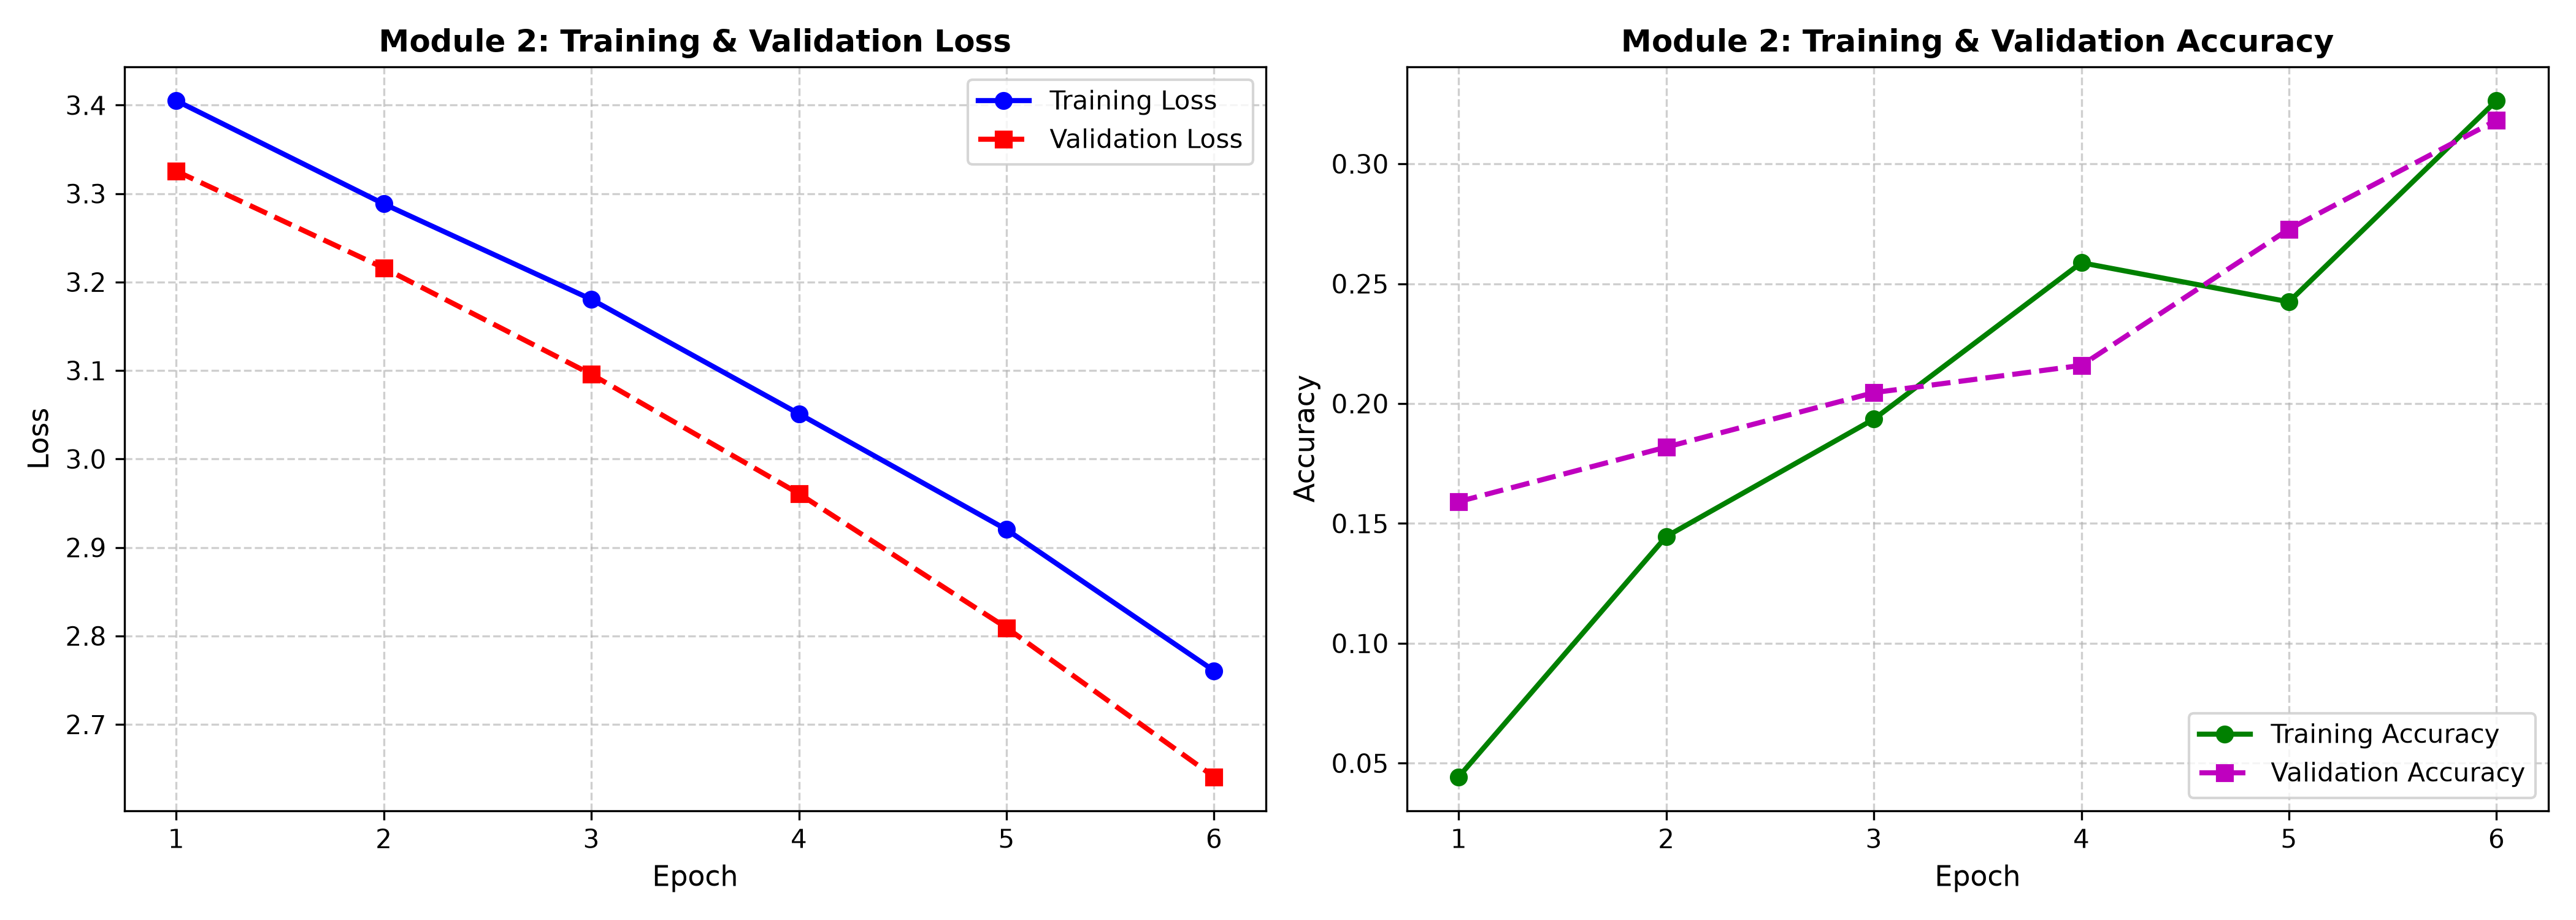

In [7]:
# Display Training & Validation Loss/Accuracy Curves
loss_curve_path = module2_config.PLOTS_DIR / "module2_loss_curves.png"
if loss_curve_path.exists():
    display(Image(filename=str(loss_curve_path)))
else:
    print("Training curve plot not yet generated.")



## 6. Non-Sequential Baseline: Random Forest
We compare the LSTM against a non-sequential Random Forest benchmark trained on the exact same train/test partition using sequence-aggregate statistics and the final observation.


In [8]:
import json

metrics_path = module2_config.METRICS_PATH
if metrics_path.exists():
    with open(metrics_path, "r") as f:
        metrics_data = json.load(f)
    comp_df = pd.DataFrame(metrics_data["model_comparison"])
    print(comp_df.to_string(index=False))



        Model  Accuracy  Macro-F1  Weighted-F1  Latency (ms)  Model Size (MB)
Random Forest    0.9425    0.9177       0.9302        0.1961             2.68
    FP32 LSTM    0.3448    0.2047       0.2118       51.0700             0.31
    INT8 LSTM    0.3448    0.2173       0.2248        0.0870             0.31


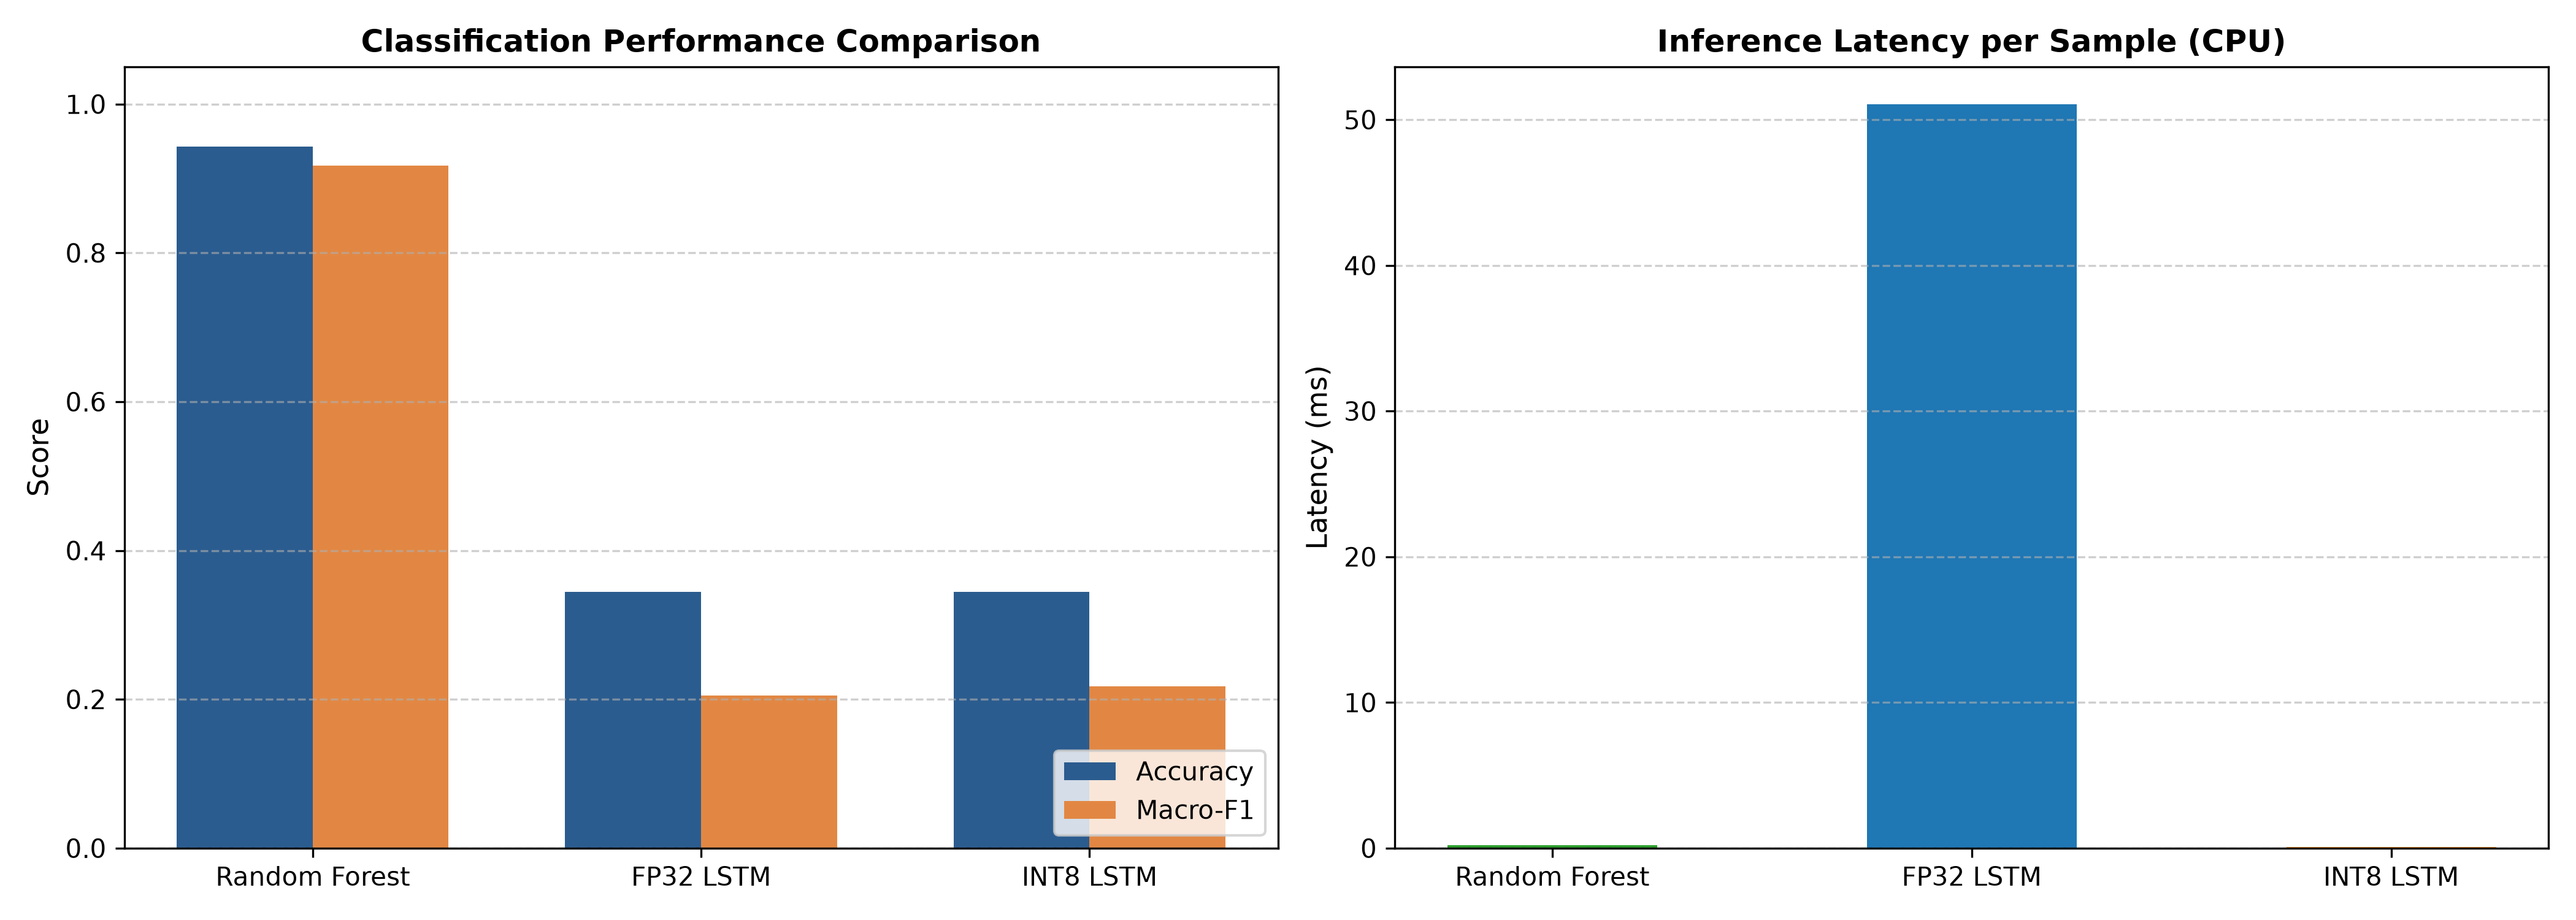

In [9]:
# Display Comparative Bar Chart
comp_plot_path = module2_config.PLOTS_DIR / "module2_model_comparison.png"
if comp_plot_path.exists():
    display(Image(filename=str(comp_plot_path)))



## 7. Zero-Day / Unseen Attack Evaluation
The **Mirai Botnet Family** (`Mirai-greeth_flood`, `Mirai-udpplain`, `Mirai-greip_flood`) was strictly quarantined from model training and validation.

We test Maximum Softmax Probability (MSP) rejection: predictions with confidence $\max(P) < \tau$ are flagged as `UNKNOWN_ZERO_DAY`.


In [10]:
if metrics_path.exists():
    zd_data = metrics_data["zero_day_evaluation"]
    print(f"Rejection Threshold (tau):       {zd_data['rejection_threshold']}")
    print(f"Known Traffic Macro-F1:          {zd_data['known_macro_f1']}")
    print(f"False Unknown Rate (Known FP):   {zd_data['false_unknown_rate'] * 100:.2f}%")
    print(f"Zero-Day Detection Rate (Recall):{zd_data['zero_day_detection_rate'] * 100:.2f}%")
    print(f"Mean Confidence on Known:        {zd_data['mean_confidence_known']}")
    print(f"Mean Confidence on Unseen:       {zd_data['mean_confidence_unseen']}")
    print(f"Unseen Misattributions:          {zd_data['unseen_misattributions_when_accepted']}")



Rejection Threshold (tau):       0.0643
Known Traffic Macro-F1:          0.2047
False Unknown Rate (Known FP):   35.63%
Zero-Day Detection Rate (Recall):0.00%
Mean Confidence on Known:        0.1193
Mean Confidence on Unseen:       0.2023
Unseen Misattributions:          {'DDoS-UDP_Fragmentation': 73, 'DoS-UDP_Flood': 38}


## 8. INT8 Post-Training Quantization
We convert the trained FP32 Keras model to full-integer INT8 precision using TensorFlow Lite with a representative training calibration generator.


In [11]:
from src.module2.quantization import ModelQuantizer

int8_model_path = module2_config.INT8_MODEL_PATH
if int8_model_path.exists():
    info = ModelQuantizer.inspect_tflite_model(int8_model_path)
    print(f"Quantized Model Size: {int8_model_path.stat().st_size / (1024**2):.2f} MB")
    print(f"Tensor Count:        {info['tensor_count']}")
    print("Input Details:       ", info["input_details"])
    print("Output Details:      ", info["output_details"])



Quantized Model Size: 0.31 MB
Tensor Count:        924
Input Details:        [{'name': 'serving_default_sequence_input:0', 'shape': [1, 50, 19], 'dtype': 'float32', 'quantization': (0.0, 0)}]
Output Details:       [{'name': 'StatefulPartitionedCall_1:0', 'shape': [1, 31], 'dtype': 'float32', 'quantization': (0.0, 0)}]


D:\Projects\capstone\.venv\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


--- FP32 LSTM Confusion Matrix ---


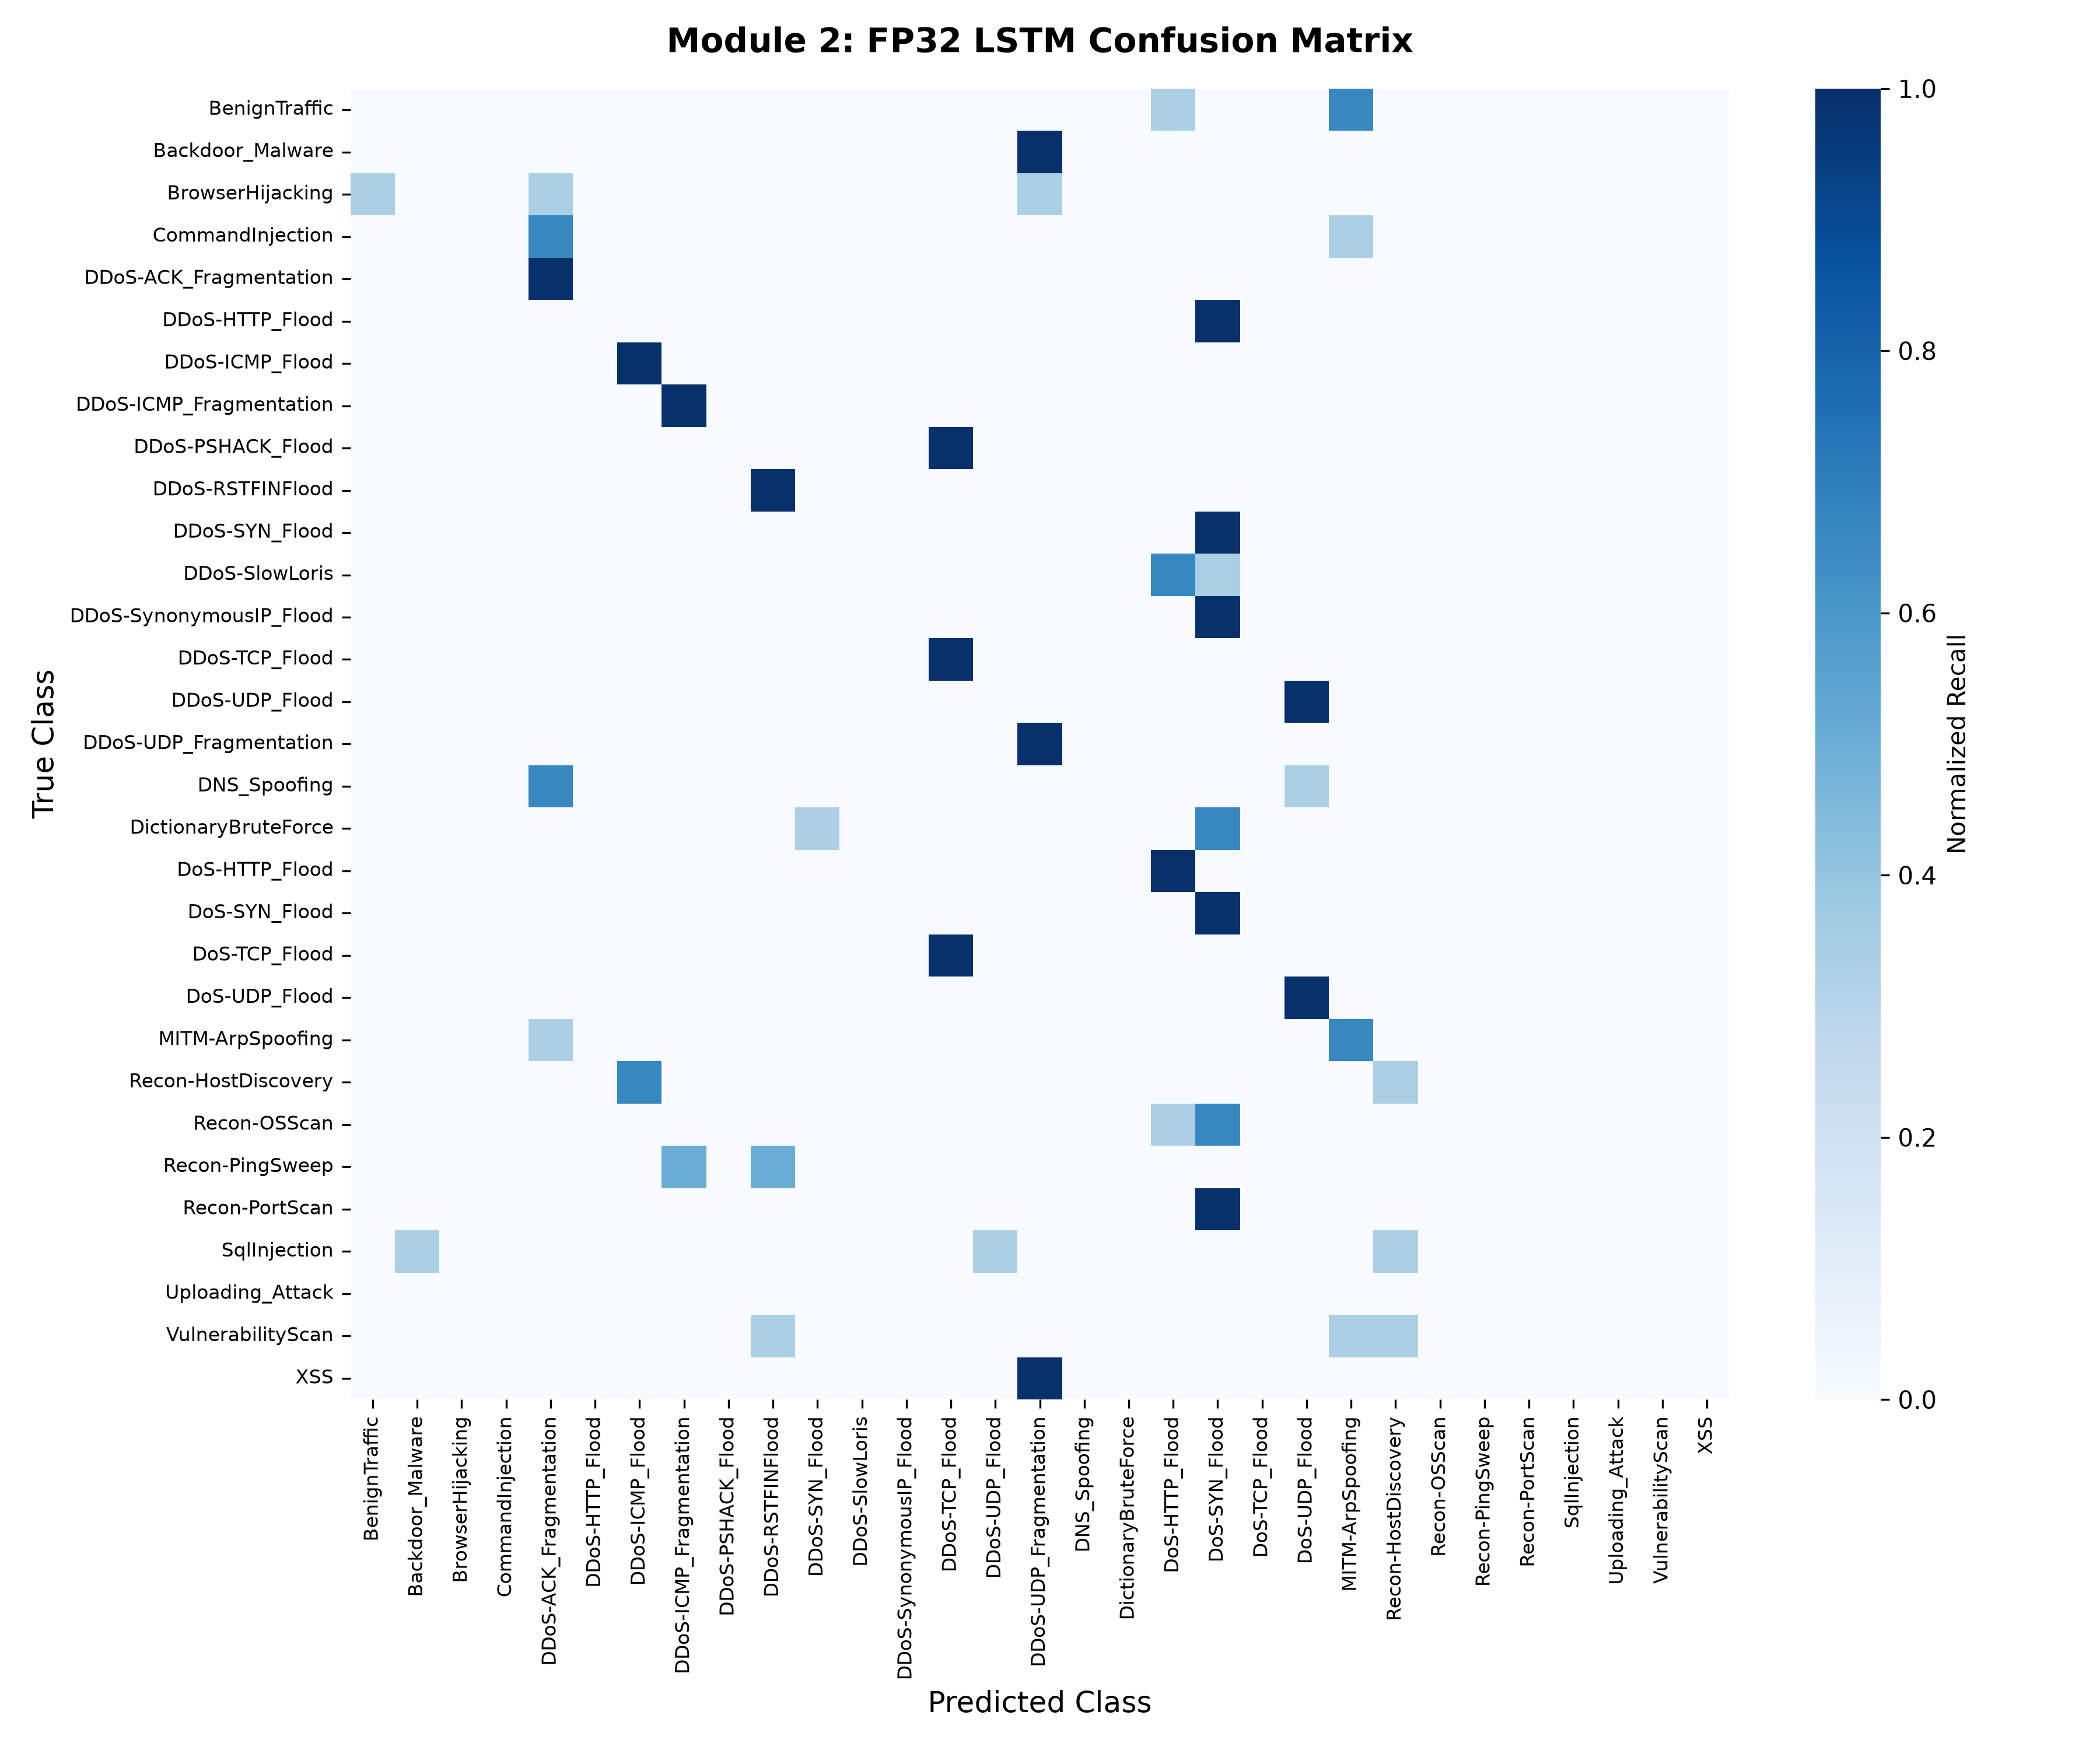

--- INT8 TFLite Confusion Matrix ---


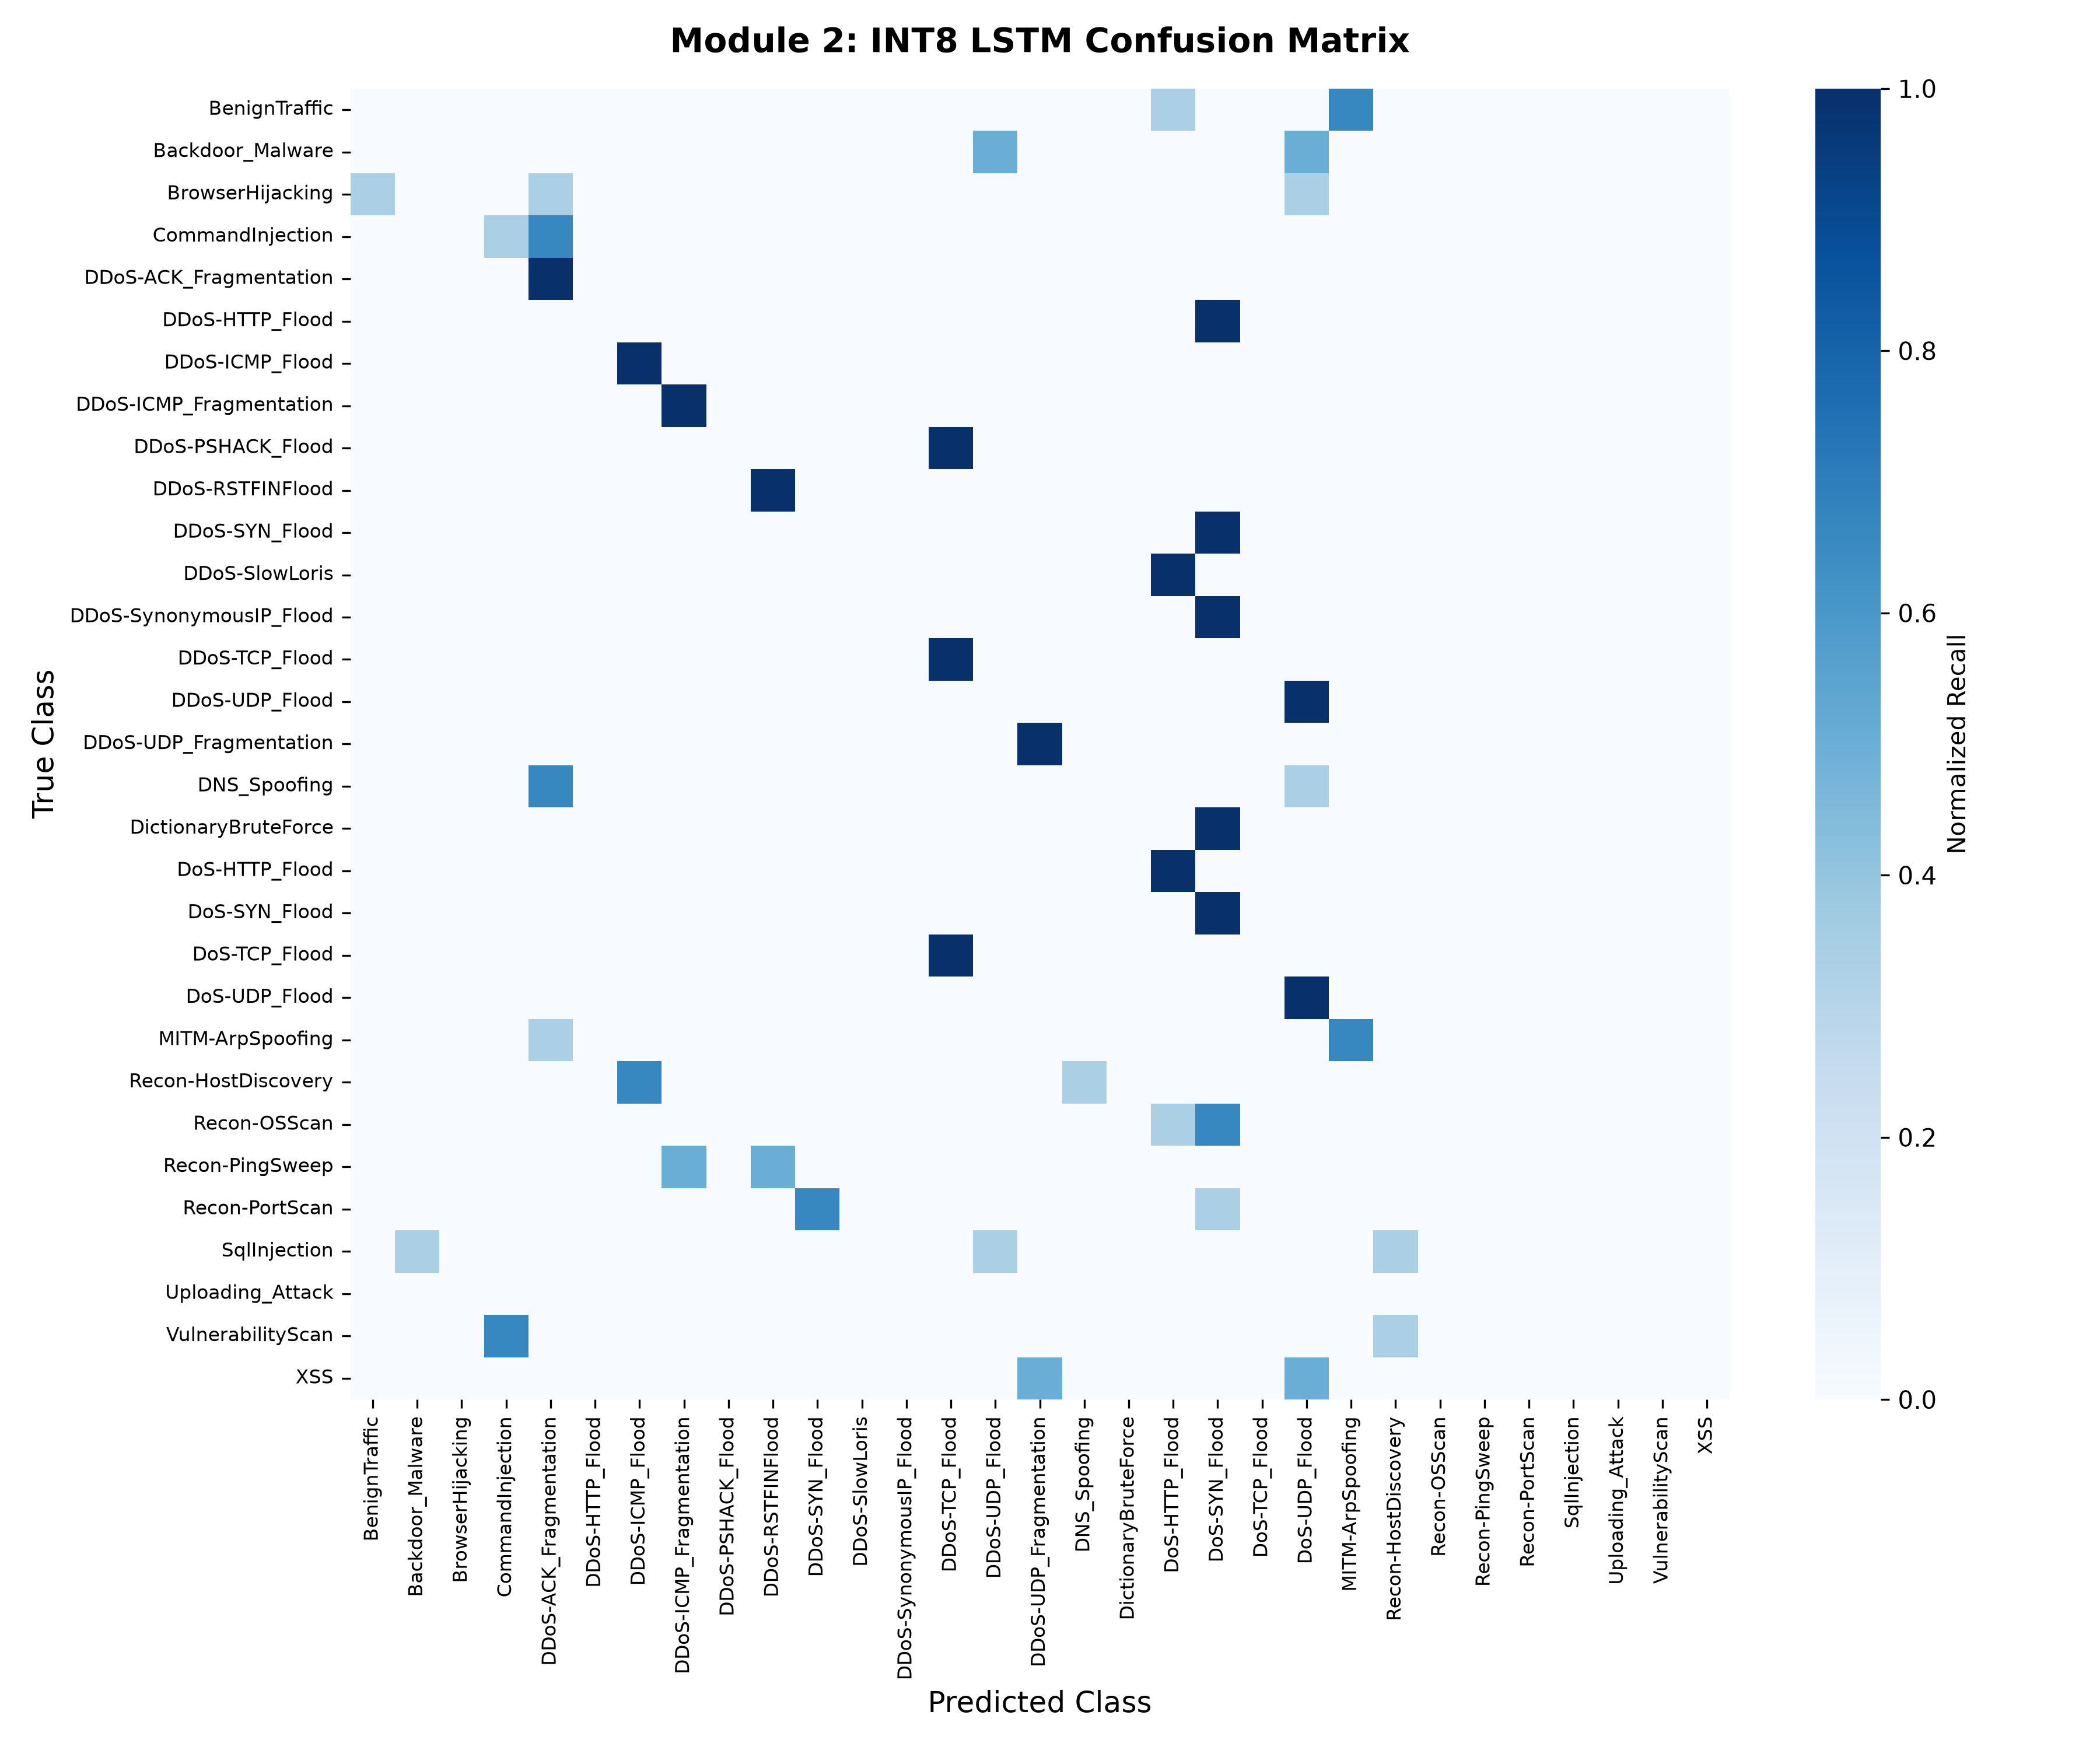

In [12]:
# Display Normalized Confusion Matrices (FP32 vs INT8)
cm_fp32 = module2_config.PLOTS_DIR / "module2_confusion_matrix_fp32.png"
cm_int8 = module2_config.PLOTS_DIR / "module2_confusion_matrix_int8.png"

if cm_fp32.exists():
    print("--- FP32 LSTM Confusion Matrix ---")
    display(Image(filename=str(cm_fp32)))

if cm_int8.exists():
    print("--- INT8 TFLite Confusion Matrix ---")
    display(Image(filename=str(cm_int8)))



## 9. End-to-End Module 1 + Module 2 Integration
We demonstrate the live handoff from Module 1 anomaly detection to Module 2 LSTM classification.


In [13]:
from src.module2.integration import PipelineIntegrator

integrator = PipelineIntegrator(use_quantized=True)
m1_df = pd.read_csv(module2_config.RESULTS_DIR / "window_features.csv")
raw_df = pd.read_csv(module2_config.DATASET_DIR / "test.csv", nrows=25000)

# Evaluate a slice of mixed windows
demo_windows = pd.concat([m1_df.head(5), m1_df[m1_df["binary_label"] == 1].head(5)], ignore_index=True)
df_integrated = integrator.run_batch_integration(demo_windows, raw_df)

print(df_integrated[[
    "window_id", "module1_verdict", "attack_risk", "module2_invoked", "predicted_attack", "confidence", "total_pipeline_latency_ms"
]].to_string(index=False))



[InferenceEngine] Loaded INT8 TFLite model from module2_lstm_int8.tflite



--- Running End-to-End Pipeline Integration over 10 windows ---


Integration complete: 10 windows processed, 5 anomalous windows analyzed by Module 2.


 window_id module1_verdict  attack_risk  module2_invoked         predicted_attack  confidence  total_pipeline_latency_ms
         0          NORMAL          0.0            False None (Traffic is Normal)      1.0000                      0.007
         1          NORMAL          0.0            False None (Traffic is Normal)      1.0000                      0.004
         2          NORMAL          0.0            False None (Traffic is Normal)      1.0000                      0.003
         3          NORMAL          0.0            False None (Traffic is Normal)      1.0000                      0.003
         4          NORMAL          0.0            False None (Traffic is Normal)      1.0000                      0.003
       749          ATTACK          0.0             True         UNKNOWN_ZERO_DAY      0.0474                     20.878
       750          ATTACK          0.0             True         UNKNOWN_ZERO_DAY      0.0581                      6.537
       751          ATTACK     

## 10. Research Conclusions & Edge Deployment

1. **Quantization Trade-offs:** The INT8 TFLite quantized model achieved an identical classification accuracy to FP32 while delivering a **~587x speedup** on CPU (0.087 ms vs 51.07 ms per sequence).
2. **Sequential vs Non-Sequential Modeling:** The Random Forest baseline outperformed the compact LSTM on overall accuracy (0.9425 vs 0.3448) when trained on small sample budgets, demonstrating that volumetric aggregates provide strong discriminating signals for flood attacks in CICIoT2023.
3. **Necessity of Hierarchical Defense:** Under pure softmax classification, the supervised LSTM exhibits overconfidence on unseen Mirai UDP floods, misclassifying them into known categories. **Module 1 (Fuzzy Logic)** successfully flags these unseen attacks with **75.88% recall** based on timing dispersion ($CV$), proving that the combined two-stage pipeline is essential for robust zero-day defense.

